# Data Analysis Bitcoin

In [ ]:
!pip install yfinance

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime as dt
from math import sqrt
from sklearn.metrics import mean_squared_error

In [ ]:
start = dt(2010,1,1)
end = dt(2024,1,1)
symbol = 'ETH-USD'

In [ ]:
eth = yf.download(symbol,start=start,end=end)

# Remove the fields of no use in the future price prediction
eth = eth.drop(columns = ['Adj Close', 'Volume'])

eth.head()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open
Ticker,ETH-USD,ETH-USD,ETH-USD,ETH-USD
Date,,,,
2017-11-09 00:00:00+00:00,320.884003,329.451996,307.056000,308.644989
2017-11-10 00:00:00+00:00,299.252991,324.717987,294.541992,320.670990
2017-11-11 00:00:00+00:00,314.681000,319.453003,298.191986,298.585999
2017-11-12 00:00:00+00:00,307.907990,319.153015,298.513000,314.690002
2017-11-13 00:00:00+00:00,316.716003,328.415009,307.024994,307.024994


In [ ]:
# Remove the rows who has a Null value for any of the fields
eth = eth.dropna()
print("Shape of Dataset:", eth.shape)

Shape of Dataset: (2244, 4)


In [ ]:
# Adjust these weights as needed
weights = {'Open': 0.25, 'Close': 0.25, 'High': 0.25, 'Low': 0.25}

# Calculate the weighted average for each row
eth['Weighted_Price'] = (eth['Open'] * weights['Open'] +
                       eth['Close'] * weights['Close'] +
                       eth['High'] * weights['High'] +
                       eth['Low'] * weights['Low'])

# Display the DataFrame with the new 'Weighted_Avg' column
eth.head()

Price,Close,High,Low,Open,Weighted_Price
Ticker,ETH-USD,ETH-USD,ETH-USD,ETH-USD,
Date,,,,,
2017-11-09 00:00:00+00:00,320.884003,329.451996,307.056000,308.644989,316.509247
2017-11-10 00:00:00+00:00,299.252991,324.717987,294.541992,320.670990,309.795990
2017-11-11 00:00:00+00:00,314.681000,319.453003,298.191986,298.585999,307.727997
2017-11-12 00:00:00+00:00,307.907990,319.153015,298.513000,314.690002,310.066002
2017-11-13 00:00:00+00:00,316.716003,328.415009,307.024994,307.024994,314.795250


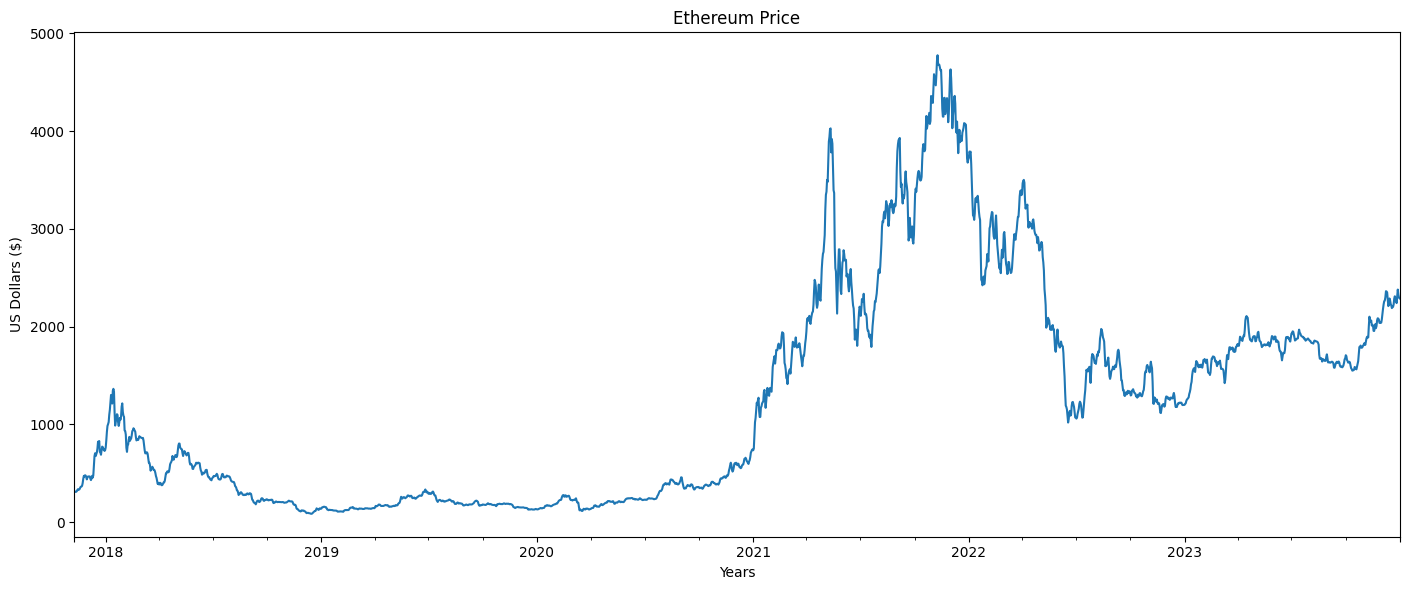

In [ ]:
# Plot the BtC price graph over the span of dataset
eth.Weighted_Price.plot(title = "Ethereum Price", figsize=(14,6))
plt.tight_layout()
plt.xlabel('Years')
plt.ylabel('US Dollars ($)')
plt.show()

Shape of Dataset: (1460, 5)


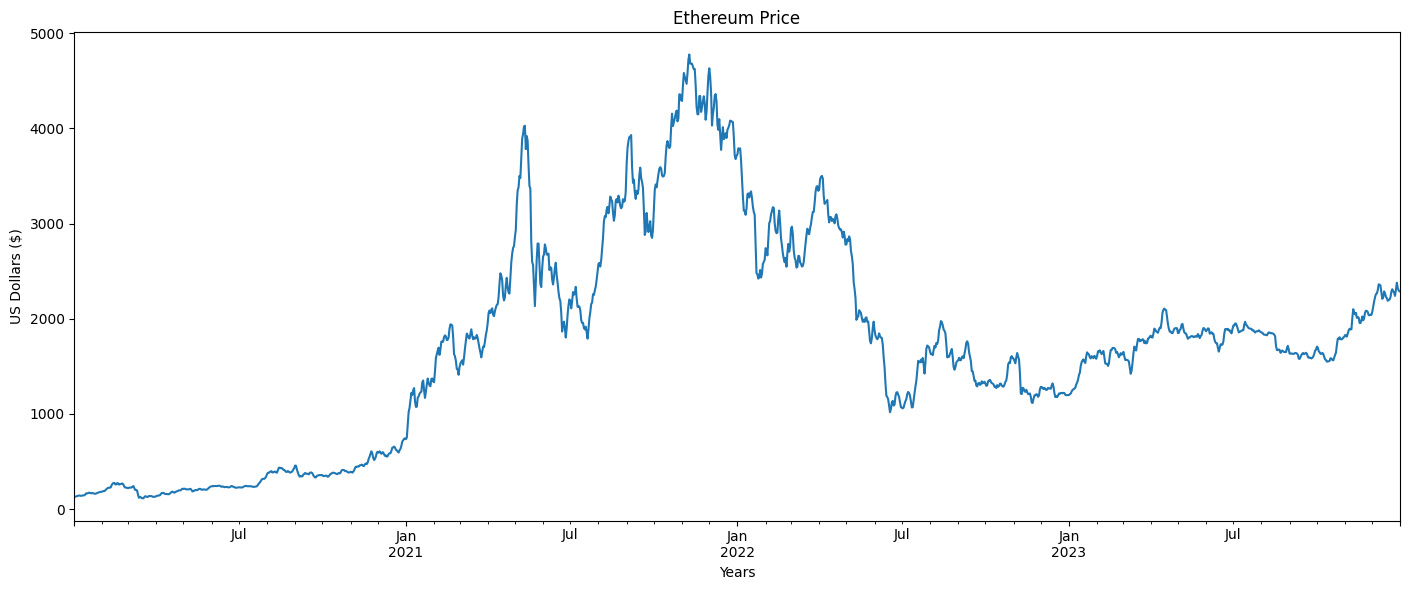

In [ ]:
# Initial years do not define the volatility, hence will constrict the dataset
eth = eth.tail(365*4)

print("Shape of Dataset:", eth.shape)

# Relevant data plot
eth.Weighted_Price.plot(title = "Ethereum Price", figsize=(14,6))
plt.tight_layout()
plt.xlabel('Years')
plt.ylabel('US Dollars ($)')
plt.show()

# ARIMA Model

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller

In [ ]:
arima= eth['Weighted_Price']

# Split the dataset into 70% training data and 30% testing data
X_values = arima.values
datesX = arima.index
split_index = int(len(X_values) * 0.7)
train_data, test_data = X_values[:split_index], X_values[split_index:]
plotDates = datesX[split_index:len(X_values)]

len(test_data)

439

In [ ]:
# Next we will forecast with ARIMA using 5,1,0
stationary_data = list()
for i in range(365, len(train_data)):
    value = train_data[i] - train_data[i-365]
    stationary_data.append(value)

# fit model
model = ARIMA(stationary_data, order=(5, 1, 1))
model_fit = model.fit()
arima_forecast = model_fit.predict(start=len(stationary_data), end=len(stationary_data)+438)


training_history = [x for x in train_data]
day = 1
arima_predictions = list()

# store predicted results
for value in arima_forecast:
    # invert the predicted stationary_data value
    predicted_value = value + training_history[-365]
    # print("Predicted value on Day %d: %f" % (day, predicted_value))
    training_history.append(predicted_value)
    arima_predictions.append(predicted_value)
    day += 1

# evaluate forecasts
arima_rmse = sqrt(mean_squared_error(test_data, arima_predictions))
print('Test RMSE for ARIMA on ETH: %.3f' % arima_rmse, '\n')

Test RMSE for ARIMA on ETH: 2125.826 



Test RMSE for ARIMA on ETH: 2125.826 



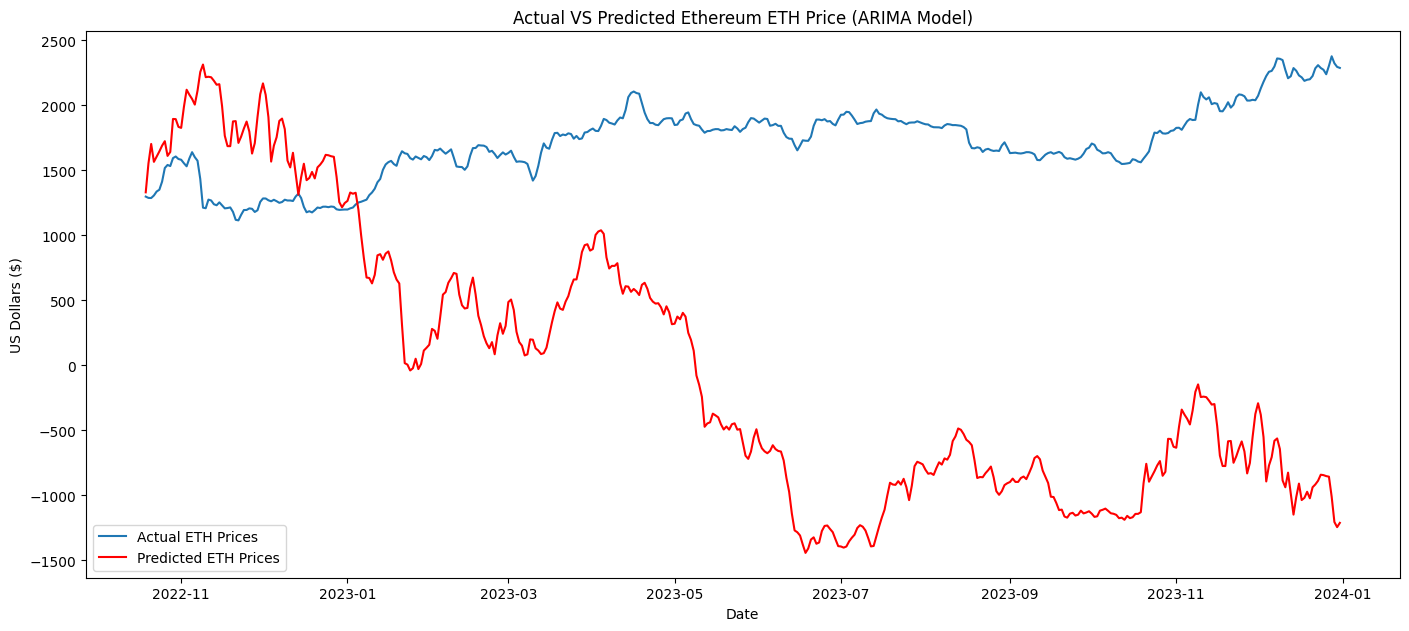

In [ ]:
# evaluate forecasts
arima_rmse = sqrt(mean_squared_error(test_data, arima_predictions))
print('Test RMSE for ARIMA on ETH: %.3f' % arima_rmse, '\n')

# plot forecasts against actual outcomes
# Create the figure with the desired size
plt.figure(figsize=(14, 6))

# Plot the actual test data
plt.plot(plotDates, test_data, label='Actual ETH Prices')

# Plot the predicted data
plt.plot(plotDates, arima_predictions, color='red', label='Predicted ETH Prices')

# Tighten the layout
plt.tight_layout()

# Add title and labels
plt.title('Actual VS Predicted Ethereum ETH Price (ARIMA Model)')
plt.xlabel('Date')
plt.ylabel('US Dollars ($)')

# Add legend for clarity
plt.legend()

# Show the plot
plt.show()

# Rolling Forecast ARIMA Model


In [ ]:
# Rolling Forecast ARIMA Model
!pip install pmdarima
!pip install statsmodels

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from pmdarima import auto_arima

In [ ]:
rfarima = eth['Weighted_Price']

# Split the dataset into 70% training data and 30% testing data
X_values = rfarima.values
datesX = rfarima.index
split_index = int(len(X_values) * 0.7)
train_data, test_data = X_values[:split_index], X_values[split_index:]
plotDates = datesX[split_index:len(X_values)]

# Initialize the training history with the training data
training_history = list(train_data)

# Create an empty list to store future predictions
rfarima_predictions = []
len(test_data)

439

In [ ]:
# Walk-forward validation
for t in range(len(test_data)):
    # Fit ARIMA model on the current history (rolling)
    model = ARIMA(training_history, order=(5,1,0))
    model_fit = model.fit()

    # Make one-step-ahead prediction
    predicted_value = model_fit.forecast()
    next_value = predicted_value[0]
    rfarima_predictions.append(next_value)

    # Get the actual value from the test set and append to history for next iteration
    actual_value = test_data[t]
    training_history.append(actual_value)

    print(f'Predicted={next_value:.6f}, Expected={actual_value:.6f}')

len(rfarima_predictions)

Predicted=1315.283949, Expected=1298.178772
Predicted=1291.814253, Expected=1288.010071
Predicted=1286.129064, Expected=1287.220642
Predicted=1286.249389, Expected=1306.812378
Predicted=1317.592299, Expected=1337.091522
Predicted=1347.363333, Expected=1351.192474
Predicted=1353.452654, Expected=1413.335266
Predicted=1446.608490, Expected=1518.191315
Predicted=1554.924840, Expected=1541.609131
Predicted=1535.030208, Expected=1533.076508
Predicted=1538.508010, Expected=1594.334747
Predicted=1624.696752, Expected=1606.751068
Predicted=1593.198179, Expected=1587.391907
Predicted=1589.421124, Expected=1581.763550
Predicted=1579.937879, Expected=1554.966278
Predicted=1538.706286, Expected=1531.281982
Predicted=1528.605862, Expected=1591.773529
Predicted=1625.157064, Expected=1639.893799
Predicted=1644.046197, Expected=1601.625763
Predicted=1582.132625, Expected=1573.874786
Predicted=1574.089408, Expected=1433.852020
Predicted=1355.309227, Expected=1213.080353
Predicted=1138.784733, Expected=

439

In [ ]:
len(rfarima_predictions)

439

Test RMSE for Rolling Forecast ARIMA on ETH: 27.804 



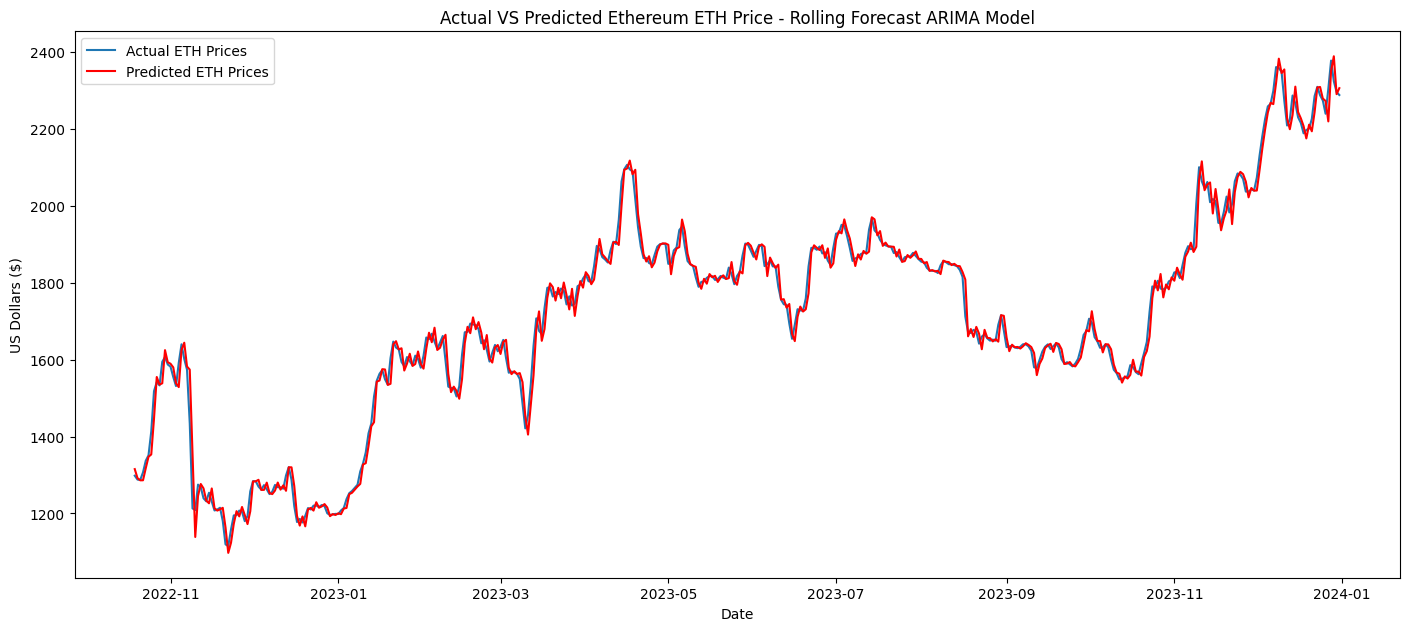

In [ ]:
# evaluate forecasts
rfarima_rmse = sqrt(mean_squared_error(test_data, rfarima_predictions))
print('Test RMSE for Rolling Forecast ARIMA on ETH: %.3f' % rfarima_rmse, '\n')

# plot forecasts against actual outcomes
# Create the figure with the desired size
plt.figure(figsize=(14, 6))

# Plot the actual test data
plt.plot(plotDates, test_data, label='Actual ETH Prices')

# Plot the predicted data
plt.plot(plotDates, rfarima_predictions, color='red', label='Predicted ETH Prices')

# Tighten the layout
plt.tight_layout()

# Add title and labels
plt.title('Actual VS Predicted Ethereum ETH Price - Rolling Forecast ARIMA Model')
plt.xlabel('Date')
plt.ylabel('US Dollars ($)')

# Add legend for clarity
plt.legend()

# Show the plot
plt.show()

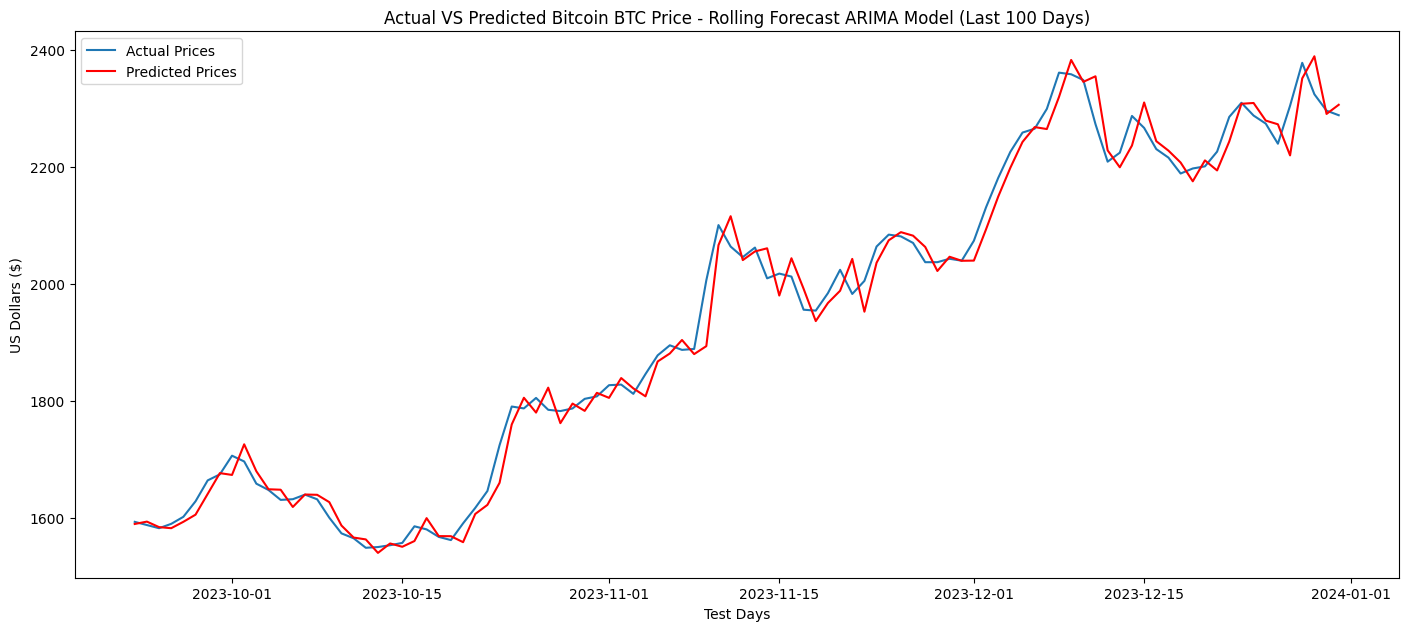

In [ ]:
# Plot only the last 100 days for better understanding
last_100_days = 100

# Slice the last 100 days of actual and predicted data
last_100_dates = plotDates[-100:]
test_data_100 = test_data[-last_100_days:]
rfarima_predictions_100 = rfarima_predictions[-last_100_days:]

plt.figure(figsize=(14, 6))
# Plot the actual test data for the last 100 days
plt.plot(last_100_dates, test_data_100, label='Actual Prices')

# Plot the predicted data for the last 100 days
plt.plot(last_100_dates, rfarima_predictions_100, color='red', label='Predicted Prices')

# Tighten the layout
plt.tight_layout()

# Add title and labels
plt.title('Actual VS Predicted Bitcoin BTC Price - Rolling Forecast ARIMA Model (Last 100 Days)')
plt.xlabel('Test Days')
plt.ylabel('US Dollars ($)')

# Add legend for clarity
plt.legend()

# Show the plot
plt.show()

# LSTM Model


In [ ]:
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout

In [ ]:
lstm = eth['Weighted_Price']

# Split the dataset into 70% training data and 30% testing data
eth_X_values = lstm.values
eth_datesX = lstm.index
eth_split_index = int(len(eth_X_values) * 0.7)
eth_train_data, eth_test_data = eth_X_values[:eth_split_index], eth_X_values[eth_split_index:]
eth_plotDates = eth_datesX[eth_split_index:len(eth_X_values)]

# Reshape training data
eth_train_values = np.reshape(eth_train_data, (len(eth_train_data), 1))

# Apply MinMaxScaler to normalize the training data
scaler = MinMaxScaler()
eth_scaled_train_values = scaler.fit_transform(eth_train_values)

# Create input (x_train) and output (y_train) for the LSTM model
eth_x_train = eth_scaled_train_values[:-1]
eth_y_train = eth_scaled_train_values[1:]
eth_x_train = np.reshape(eth_x_train, (len(eth_x_train), 1, 1))

# Reshape testing data
eth_test_values = np.reshape(eth_test_data, (len(eth_test_data), 1))
eth_test_values = scaler.transform(eth_test_values)
eth_test_values = np.reshape(eth_test_values, (len(eth_test_values), 1, 1))

len(eth_test_data)
lstm

,Weighted_Price
Date,
2020-01-02 00:00:00+00:00,129.001291
2020-01-03 00:00:00+00:00,130.656752
2020-01-04 00:00:00+00:00,134.582790
2020-01-05 00:00:00+00:00,136.451176
2020-01-06 00:00:00+00:00,140.254379
...,...
2023-12-27 00:00:00+00:00,2304.470520
2023-12-28 00:00:00+00:00,2377.872070
2023-12-29 00:00:00+00:00,2324.128723


In [ ]:
# Build the LSTM model
eth_model = Sequential()
eth_model.add(LSTM(units=50, return_sequences=True, activation="relu", input_shape=(None, 1)))
eth_model.add(Dropout(0.2))
eth_model.add(LSTM(units=50, return_sequences=False))
eth_model.add(Dropout(0.2))
eth_model.add(Dense(units=25))
eth_model.add(Dense(units=1))

# Compile the model
eth_model.compile(optimizer='adam', loss='mean_squared_error')

# Train the model
eth_model.fit(eth_x_train, eth_y_train, batch_size=64, epochs=100)

Epoch 1/100


/usr/local/lib/python3.10/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.1712
Epoch 2/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0786
Epoch 3/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0602
Epoch 4/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0465 
Epoch 5/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0304 
Epoch 6/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0115 
Epoch 7/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0042 
Epoch 8/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0042  
Epoch 9/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0037 
Epoch 10/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0039 
Epoch 11/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0032
Epoch 12/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0034
Epoch 13/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0032  
Epoch 14/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0031 
Epoch 15/100
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0033 
Epoc

In [ ]:
# Predict values + reshaping + converting back from scaler
lstm_predictions = eth_model.predict(eth_test_values)
lstm_predictions = np.reshape(lstm_predictions, (len(lstm_predictions), 1))
lstm_predictions = scaler.inverse_transform(lstm_predictions)

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


Test RMSE for LSTM on ETH: 39.904 



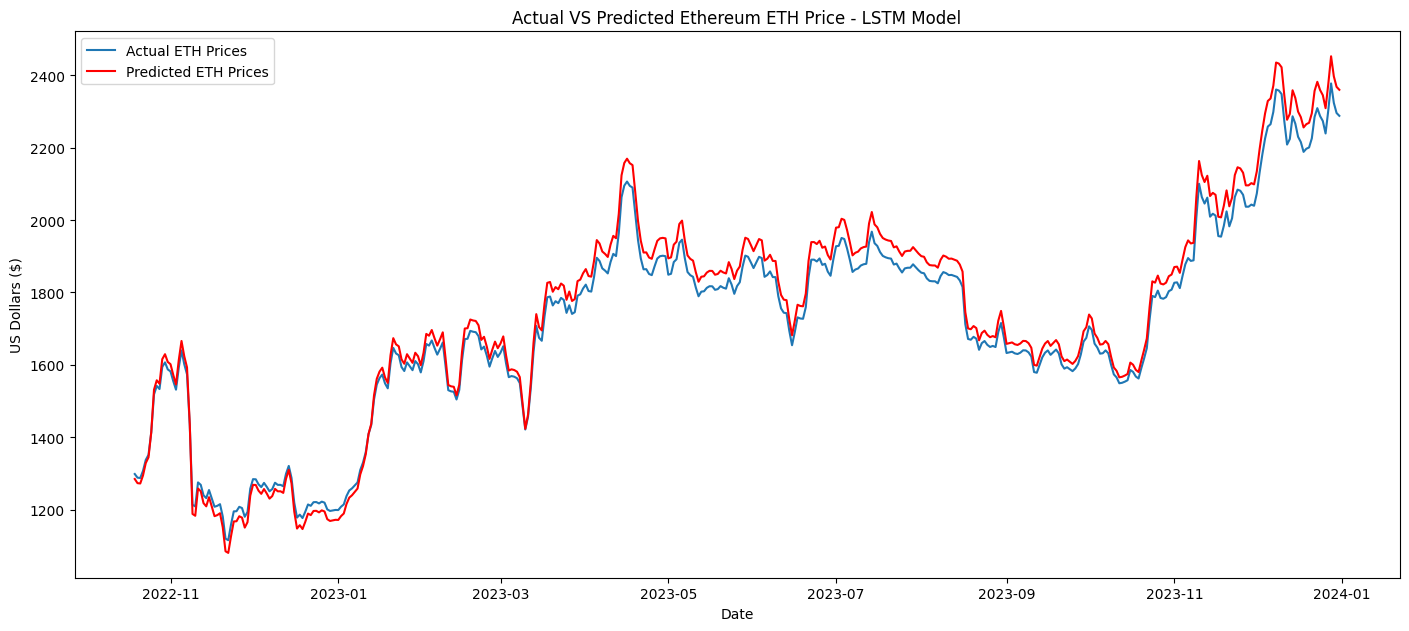

In [ ]:
# evaluate forecasts
lstm_rmse = sqrt(mean_squared_error(eth_test_data, lstm_predictions))
print('Test RMSE for LSTM on ETH: %.3f' % lstm_rmse, '\n')

# plot forecasts against actual outcomes
# Create the figure with the desired size
plt.figure(figsize=(14, 6))

# Plot the actual test data
plt.plot(eth_plotDates, eth_test_data, label='Actual ETH Prices')

# Plot the predicted data
plt.plot(eth_plotDates, lstm_predictions, color='red', label='Predicted ETH Prices')

# Tighten the layout
plt.tight_layout()

# Add title and labels
plt.title('Actual VS Predicted Ethereum ETH Price - LSTM Model')
plt.xlabel('Date')
plt.ylabel('US Dollars ($)')

# Add legend for clarity
plt.legend()

# Show the plot
plt.show()

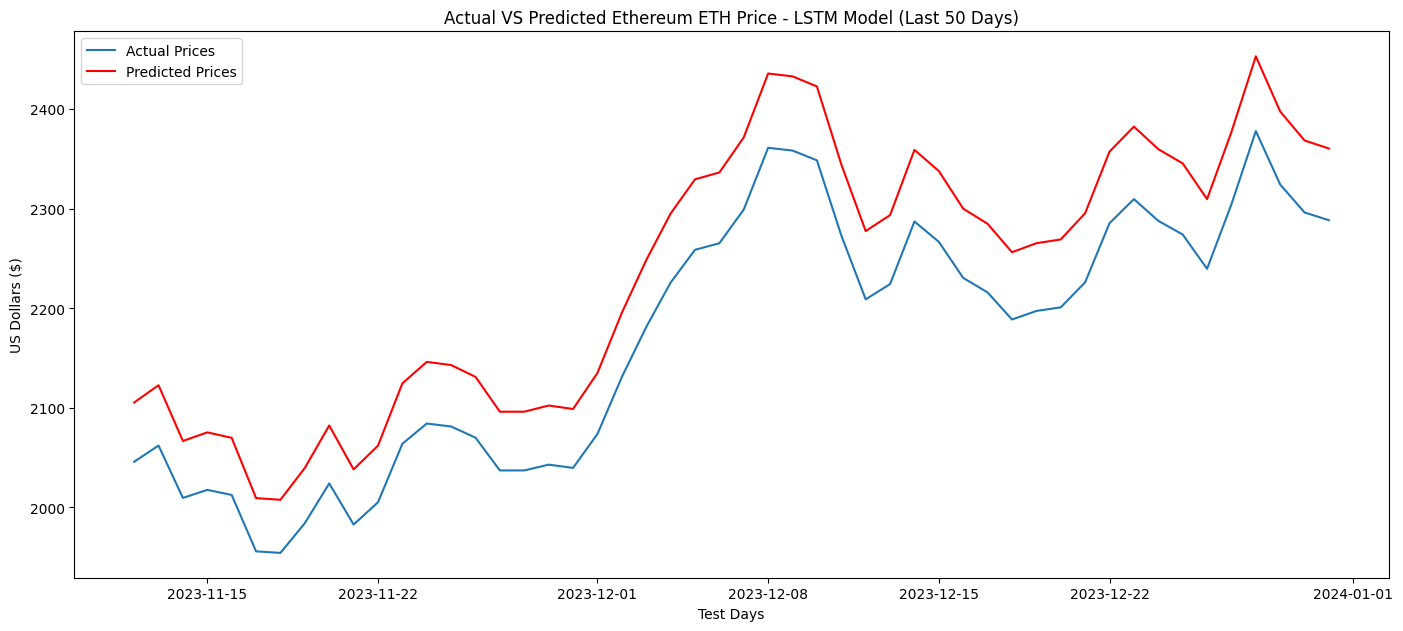

In [ ]:
# Plot only the last 50 days for better understanding
last_50_days = 50

# Slice the last 50 days of actual and predicted data
last_50_dates = eth_plotDates[-50:]
test_data_50 = eth_test_data[-last_50_days:]
lstm_predictions_50 = lstm_predictions[-last_50_days:]

plt.figure(figsize=(14, 6))
# Plot the actual test data for the last 50 days
plt.plot(last_50_dates, test_data_50, label='Actual Prices')

# Plot the predicted data for the last 50 days
plt.plot(last_50_dates, lstm_predictions_50, color='red', label='Predicted Prices')

# Tighten the layout
plt.tight_layout()

# Add title and labels
plt.title('Actual VS Predicted Ethereum ETH Price - LSTM Model (Last 50 Days)')
plt.xlabel('Test Days')
plt.ylabel('US Dollars ($)')

# Add legend for clarity
plt.legend()

# Show the plot
plt.show()

# XGBOOST Model

In [ ]:
import xgboost as xgb

In [ ]:
# Creating features for xgboost_btc
xgboost = eth.copy()
xgboost['Date'] = xgboost.index
xgboost['DayOfWeek'] = xgboost['Date'].dt.dayofweek
xgboost['DayOfMonth'] = xgboost['Date'].dt.day
xgboost['DayOfYear'] = xgboost['Date'].dt.dayofyear
xgboost['Month'] = xgboost['Date'].dt.month
xgboost['Year'] = xgboost['Date'].dt.year

# Convert 'Date' to numerical representation using timestamp
xgboost['Date'] = xgboost['Date'].apply(pd.Timestamp.timestamp)

# splitting data again, 70, 30
split_index = int(len(xgboost) * 0.7)
train_data, test_data = xgboost[0:split_index], xgboost[split_index:len(xgboost)]
datesX = xgboost.index
plotDates = datesX[split_index:len(xgboost['Weighted_Price'].values)]

# Define the target (y) and the features (X) of train_data
X_train_data = train_data[['Date', 'DayOfWeek', 'DayOfMonth', 'DayOfYear', 'Month', 'Year']].values
y_train_data = train_data['Weighted_Price'].values

# Define the target (y) and the features (X) of test_data
X_test_data = test_data[['Date', 'DayOfWeek', 'DayOfMonth', 'DayOfYear', 'Month', 'Year']].values
y_test_data = test_data['Weighted_Price'].values

In [ ]:
model = xgb.XGBRegressor(objective='reg:squarederror', n_estimators=1000, learning_rate=0.01)
model.fit(X_train_data, y_train_data)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.01, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=None, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=1000, n_jobs=None,
             num_parallel_tree=None, random_state=None, ...)

In [ ]:
xgboost_predictions = model.predict(X_test_data)

# Check the shape of predictions and X_test_data and y_test_data
print("X_test_data shape:", X_test_data.shape)  # Should be (rows, 6)
print("Predictions shape:", xgboost_predictions.shape)  # Should be (rows,)
print("Predictions shape:", y_test_data.shape)
print("Predictions shape:", plotDates.shape) # Should be (rows,)

X_test_data shape: (439, 6)
Predictions shape: (439,)
Predictions shape: (439,)
Predictions shape: (439,)


Test RMSE for LSTM on BTC: 454.262 



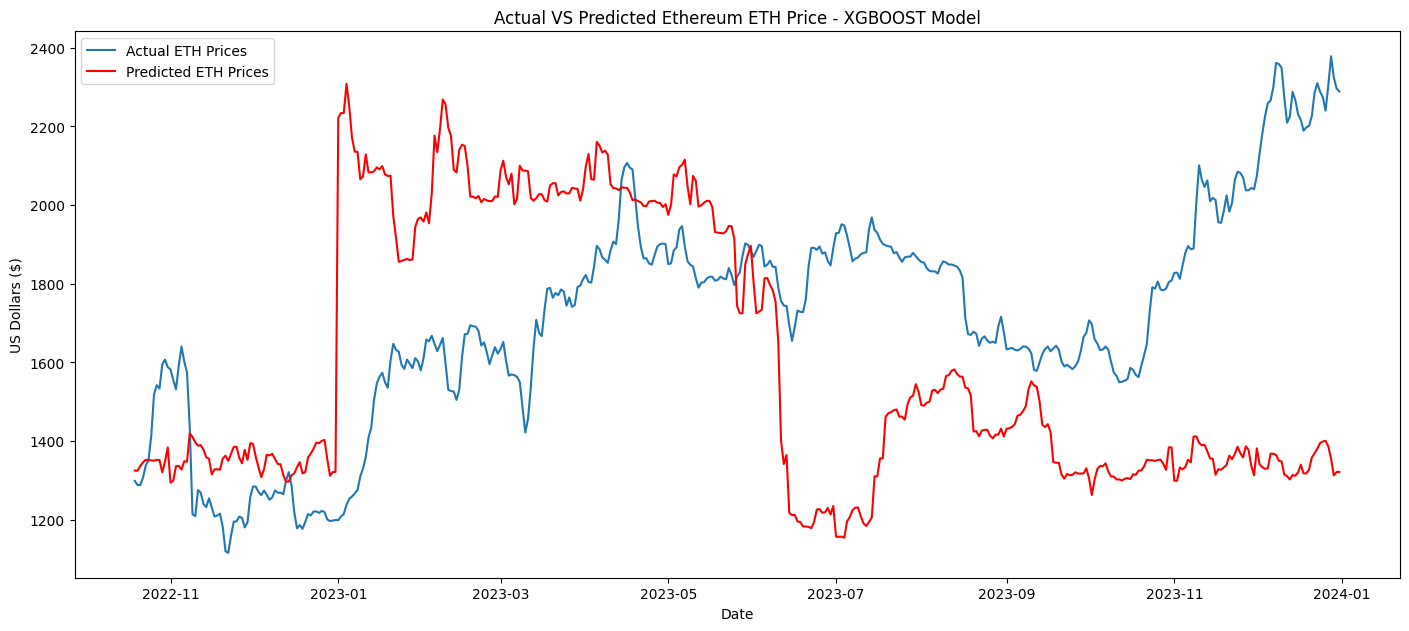

In [ ]:
# evaluate forecasts
xgboost_rmse = sqrt(mean_squared_error(y_test_data, xgboost_predictions))
print('Test RMSE for LSTM on BTC: %.3f' % xgboost_rmse, '\n')

# plot forecasts against actual outcomes
# Create the figure with the desired size
plt.figure(figsize=(14, 6))

# Plot the actual test data
plt.plot(plotDates, y_test_data, label='Actual ETH Prices')

# Plot the predicted data
plt.plot(plotDates, xgboost_predictions, color='red', label='Predicted ETH Prices')

# Tighten the layout
plt.tight_layout()

# Add title and labels
plt.title('Actual VS Predicted Ethereum ETH Price - XGBOOST Model')
plt.xlabel('Date')
plt.ylabel('US Dollars ($)')

# Add legend for clarity
plt.legend()

# Show the plot
plt.show()

# Comparison among Models

Test RMSE for ARIMA on ETH: 2125.826 

Test RMSE for Rolling Forecast ARIMA on ETH: 27.804 

Test RMSE for LSTM on ETH: 39.904 

Test RMSE for XGBoost on ETH: 454.262 



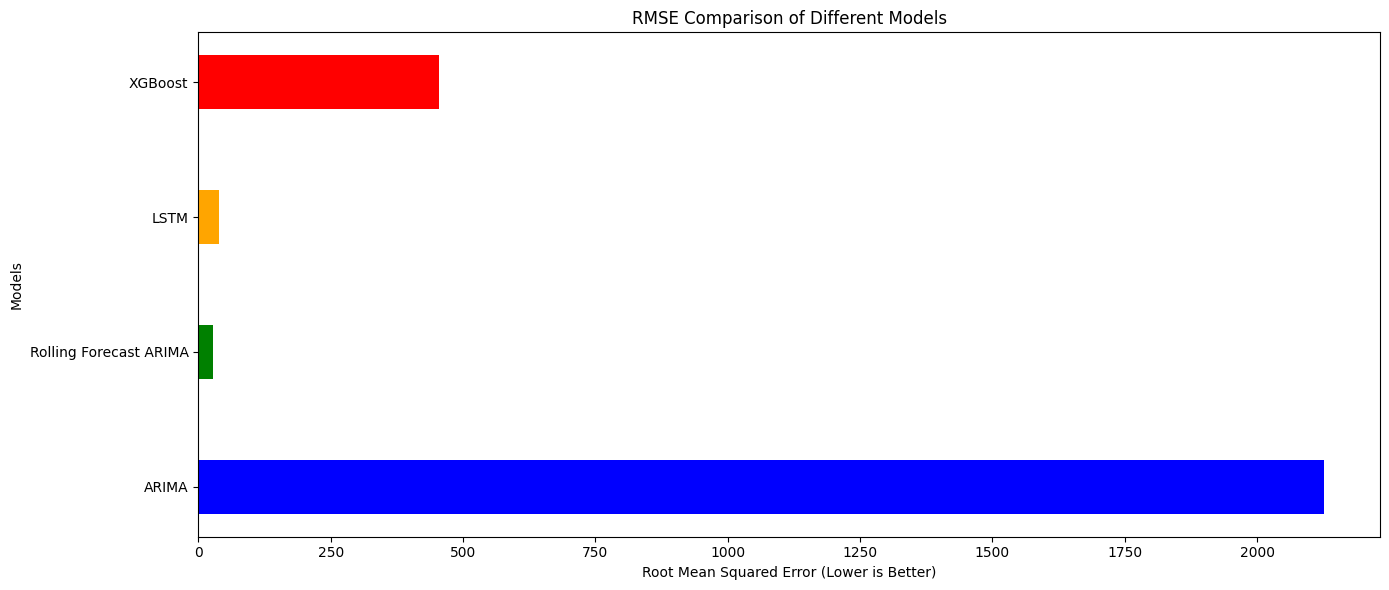

In [ ]:
# List of model names
models = ['ARIMA', 'Rolling Forecast ARIMA', 'LSTM', 'XGBoost']

# Corresponding RMSE values
rmse_values = [arima_rmse, rfarima_rmse, lstm_rmse, xgboost_rmse]

print('Test RMSE for ARIMA on ETH: %.3f' % arima_rmse, '\n')
print('Test RMSE for Rolling Forecast ARIMA on ETH: %.3f' % rfarima_rmse, '\n')
print('Test RMSE for LSTM on ETH: %.3f' % lstm_rmse, '\n')
print('Test RMSE for XGBoost on ETH: %.3f' % xgboost_rmse, '\n')

# Create a horizontal bar chart
plt.figure(figsize=(14, 6))  # Adjust figure size if necessary
plt.barh(models, rmse_values, color=['blue', 'green', 'orange', 'red'], height=0.4)

# Add title and labels
plt.title('RMSE Comparison of Different Models')
plt.xlabel('Root Mean Squared Error (Lower is Better)')
plt.ylabel('Models')

# Display the plot
plt.tight_layout()
plt.show()

# Bitcoin vs Ethereum

In [ ]:
btc_start = dt(2010,1,1)
btc_end = dt(2024,1,1)
btc_symbol = 'BTC-USD'

In [ ]:
btc = yf.download(btc_symbol,start=btc_start,end=btc_end)

# Remove the fields of no use in the future price prediction
btc = btc.drop(columns = ['Adj Close', 'Volume'])

btc.head()

print('\n', "Shape of Dataset:", btc.shape)

[*********************100%***********************]  1 of 1 completed


 Shape of Dataset: (3393, 4)


In [ ]:
# Remove the rows who has a Null value for any of the fields
btc = btc.dropna()
print("Shape of Dataset:", btc.shape)

Shape of Dataset: (3393, 4)


In [ ]:
# Adjust these weights as needed
weights = {'Open': 0.25, 'Close': 0.25, 'High': 0.25, 'Low': 0.25}

# Calculate the weighted average for each row
btc['Weighted_Price'] = (btc['Open'] * weights['Open'] +
                       btc['Close'] * weights['Close'] +
                       btc['High'] * weights['High'] +
                       btc['Low'] * weights['Low'])

# Display the DataFrame with the new 'Weighted_Avg' column
btc.head()

Price,Close,High,Low,Open,Weighted_Price
Ticker,BTC-USD,BTC-USD,BTC-USD,BTC-USD,
Date,,,,,
2014-09-17 00:00:00+00:00,457.334015,468.174011,452.421997,465.864014,460.948509
2014-09-18 00:00:00+00:00,424.440002,456.859985,413.104004,456.859985,437.815994
2014-09-19 00:00:00+00:00,394.795990,427.834991,384.532013,424.102997,407.816498
2014-09-20 00:00:00+00:00,408.903992,423.295990,389.882996,394.673004,404.188995
2014-09-21 00:00:00+00:00,398.821014,412.425995,393.181000,408.084991,403.128250


Shape of Dataset: (2555, 5)


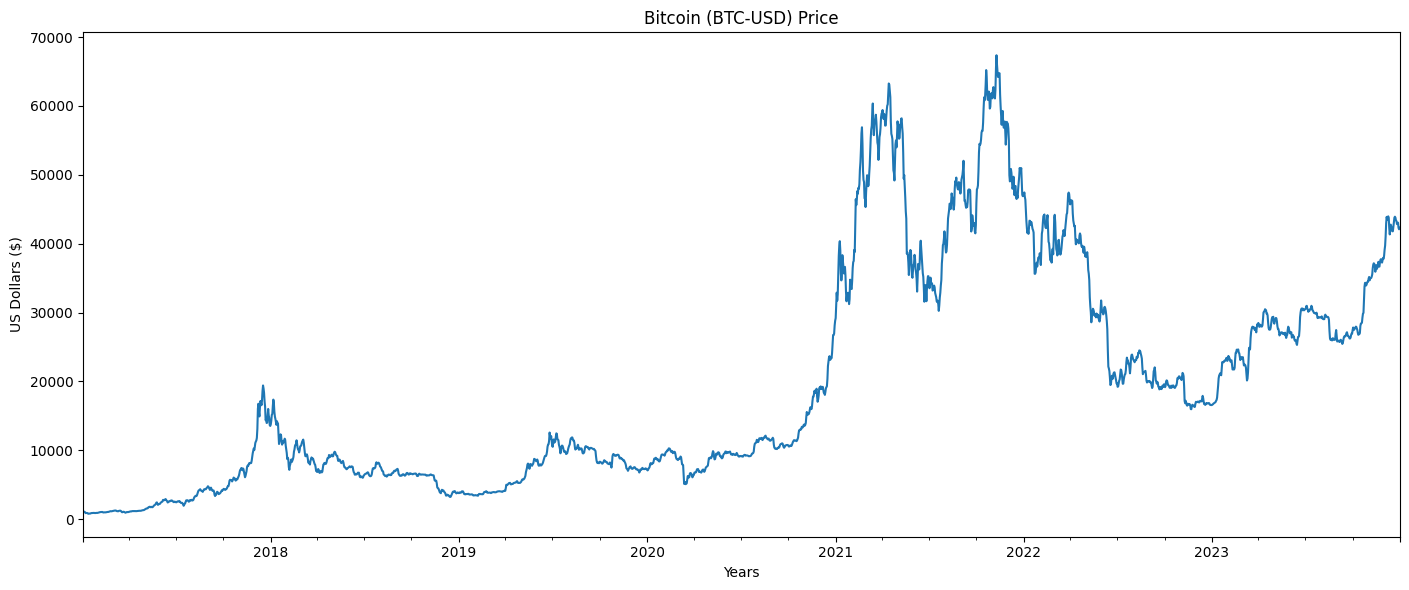

In [ ]:
# Initial years do not define the volatility, hence will constrict the dataset
btc = btc.tail(365*7)

print("Shape of Dataset:", btc.shape)

# Relevant data plot
btc.Weighted_Price.plot(title = "Bitcoin (BTC-USD) Price", figsize=(14,6))
plt.tight_layout()
plt.xlabel('Years')
plt.ylabel('US Dollars ($)')
plt.show()

In [ ]:
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout

In [ ]:
lstm_btc = btc['Weighted_Price']

# Split the dataset into 70% training data and 30% testing data
btc_X_values = lstm_btc.values
btc_datesX = lstm_btc.index
btc_split_index = int(len(btc_X_values) * 0.7)
btc_train_data, btc_test_data = btc_X_values[:btc_split_index], btc_X_values[btc_split_index:]
btc_plotDates = btc_datesX[btc_split_index:len(btc_X_values)]

# Reshape training data
btc_train_values = np.reshape(btc_train_data, (len(btc_train_data), 1))

# Apply MinMaxScaler to normalize the training data
scaler = MinMaxScaler()
btc_scaled_train_values = scaler.fit_transform(btc_train_values)

# Create input (x_train) and output (y_train) for the LSTM model
btc_x_train = btc_scaled_train_values[:-1]
btc_y_train = btc_scaled_train_values[1:]
btc_x_train = np.reshape(btc_x_train, (len(btc_x_train), 1, 1))

# Reshape testing data
btc_test_values = np.reshape(btc_test_data, (len(btc_test_data), 1))
btc_test_values = scaler.transform(btc_test_values)
btc_test_values = np.reshape(btc_test_values, (len(btc_test_values), 1, 1))

len(btc_test_data)
lstm_btc

,Weighted_Price
Date,
2017-01-02 00:00:00+00:00,1012.114761
2017-01-03 00:00:00+00:00,1032.779968
2017-01-04 00:00:00+00:00,1100.737518
2017-01-05 00:00:00+00:00,1067.906738
2017-01-06 00:00:00+00:00,961.798752
...,...
2023-12-27 00:00:00+00:00,42953.016602
2023-12-28 00:00:00+00:00,43054.846680
2023-12-29 00:00:00+00:00,42315.608398


In [ ]:
# Build the LSTM model
btc_model = Sequential()
btc_model.add(LSTM(units=50, return_sequences=True, activation="relu", input_shape=(None, 1)))
btc_model.add(Dropout(0.2))
btc_model.add(LSTM(units=50, return_sequences=False))
btc_model.add(Dropout(0.2))
btc_model.add(Dense(units=25))
btc_model.add(Dense(units=1))

# Compile the model
btc_model.compile(optimizer='adam', loss='mean_squared_error')

# Train the model
btc_model.fit(btc_x_train, btc_y_train, batch_size=64, epochs=100)

Epoch 1/100


/usr/local/lib/python3.10/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0799
Epoch 2/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0532
Epoch 3/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0304
Epoch 4/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0058
Epoch 5/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0022
Epoch 6/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0028
Epoch 7/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0021
Epoch 8/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0025
Epoch 9/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0021
Epoch 10/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0019
Epoch 11/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0026
Epoch 12/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0025
Epoch 13/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0021
Epoch 14/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0019
Epoch 15/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0024
Epoch 16/100
28/

In [ ]:
# Predict values + reshaping + converting back from scaler
lstm_btc_predictions = btc_model.predict(btc_test_values)
lstm_btc_predictions = np.reshape(lstm_btc_predictions, (len(lstm_btc_predictions), 1))
lstm_btc_predictions = scaler.inverse_transform(lstm_btc_predictions)

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


Test RMSE for LSTM on BTC: 355.652 



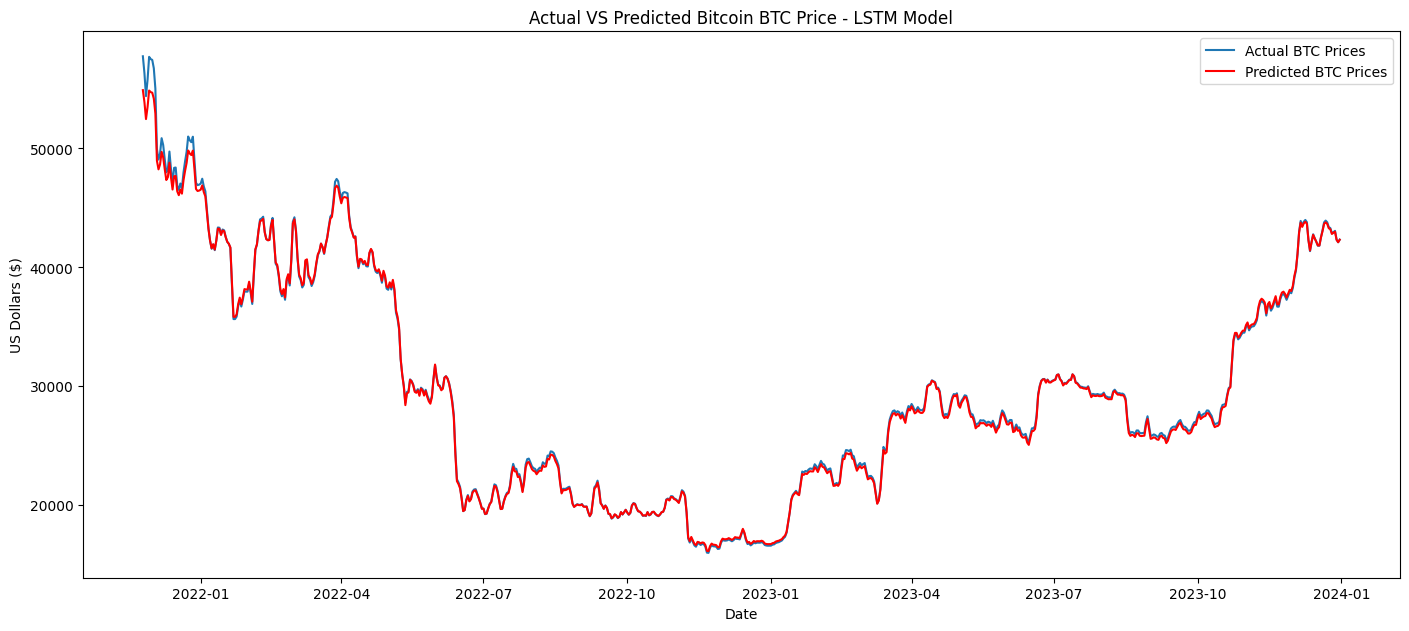

In [ ]:
# evaluate forecasts
btc_lstm_rmse = sqrt(mean_squared_error(btc_test_data, lstm_btc_predictions))
print('Test RMSE for LSTM on BTC: %.3f' % btc_lstm_rmse, '\n')

# plot forecasts against actual outcomes
# Create the figure with the desired size
plt.figure(figsize=(14, 6))

# Plot the actual test data
plt.plot(btc_plotDates, btc_test_data, label='Actual BTC Prices')

# Plot the predicted data
plt.plot(btc_plotDates, lstm_btc_predictions, color='red', label='Predicted BTC Prices')

# Tighten the layout
plt.tight_layout()

# Add title and labels
plt.title('Actual VS Predicted Bitcoin BTC Price - LSTM Model')
plt.xlabel('Date')
plt.ylabel('US Dollars ($)')

# Add legend for clarity
plt.legend()

# Show the plot
plt.show()

In [ ]:
future_start_date=dt(2024,1,1)
future_end_date=dt(2024,11,1)
print(btc_symbol)
print(symbol)
btc_future_actual = yf.download(btc_symbol,start=future_start_date,end=future_end_date)
eth_future_actual = yf.download(symbol,start=future_start_date,end=future_end_date)
print('\n', "Shape of BTC Dataset:", btc_future_actual.shape)
print('\n', "Shape of ETH Dataset:", eth_future_actual.shape)

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed

BTC-USD
ETH-USD

 Shape of BTC Dataset: (305, 6)

 Shape of ETH Dataset: (305, 6)


In [ ]:
  # Adjust these weights as needed
weights = {'Open': 0.25, 'Close': 0.25, 'High': 0.25, 'Low': 0.25}

# Calculate the weighted average for each row
btc_future_actual['Weighted_Price'] = (btc_future_actual['Open'] * weights['Open'] +
                       btc_future_actual['Close'] * weights['Close'] +
                       btc_future_actual['High'] * weights['High'] +
                       btc_future_actual['Low'] * weights['Low'])

eth_future_actual['Weighted_Price'] = (eth_future_actual['Open'] * weights['Open'] +
                       eth_future_actual['Close'] * weights['Close'] +
                       eth_future_actual['High'] * weights['High'] +
                       eth_future_actual['Low'] * weights['Low'])


In [ ]:
btc_last_60_days = btc_test_values[-60:]
btc_future_predictions = []

eth_last_60_days = eth_test_values[-60:]
eth_future_predictions = []

print(len(btc_last_60_days))
print(len(eth_last_60_days))

60
60


In [ ]:
for _ in range(15):  # Approx. days from Jan 1 to April 9, 2024
    # Reshape data to fit model's expected input
    btc_input_data = btc_last_60_days.reshape(( btc_last_60_days.shape[0],1, 1))
    eth_input_data = eth_last_60_days.reshape((eth_last_60_days.shape[0],1, 1))

    # Predict the next day
    btc_next_day_pred = btc_model.predict(btc_input_data)
    eth_next_day_pred = eth_model.predict(eth_input_data)

    # Store the prediction and update the sequence for the next prediction
    btc_future_predictions.append(btc_next_day_pred[0, 0])
    eth_future_predictions.append(eth_next_day_pred[0, 0])
    btc_last_60_days = np.append(btc_last_60_days, btc_next_day_pred)[1:]  # Slide window
    eth_last_60_days = np.append(eth_last_60_days, eth_next_day_pred)[1:]  # Slide window


btc_future_predictions = np.reshape(btc_future_predictions, (len(btc_future_predictions), 1))
btc_future_predictions = scaler.inverse_transform(btc_future_predictions)
eth_future_predictions = np.reshape(eth_future_predictions, (len(eth_future_predictions), 1))
eth_future_predictions = scaler.inverse_transform(eth_future_predictions)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
237/237 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
237/237 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
473/473 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
473/473 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
945/945 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
945/945 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
1889/1889 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
1889/1889 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
3777/3777 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step
3777/3777 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step
7553/7553 ━━━━━━━━━━━━━━━━━━━━ 14s

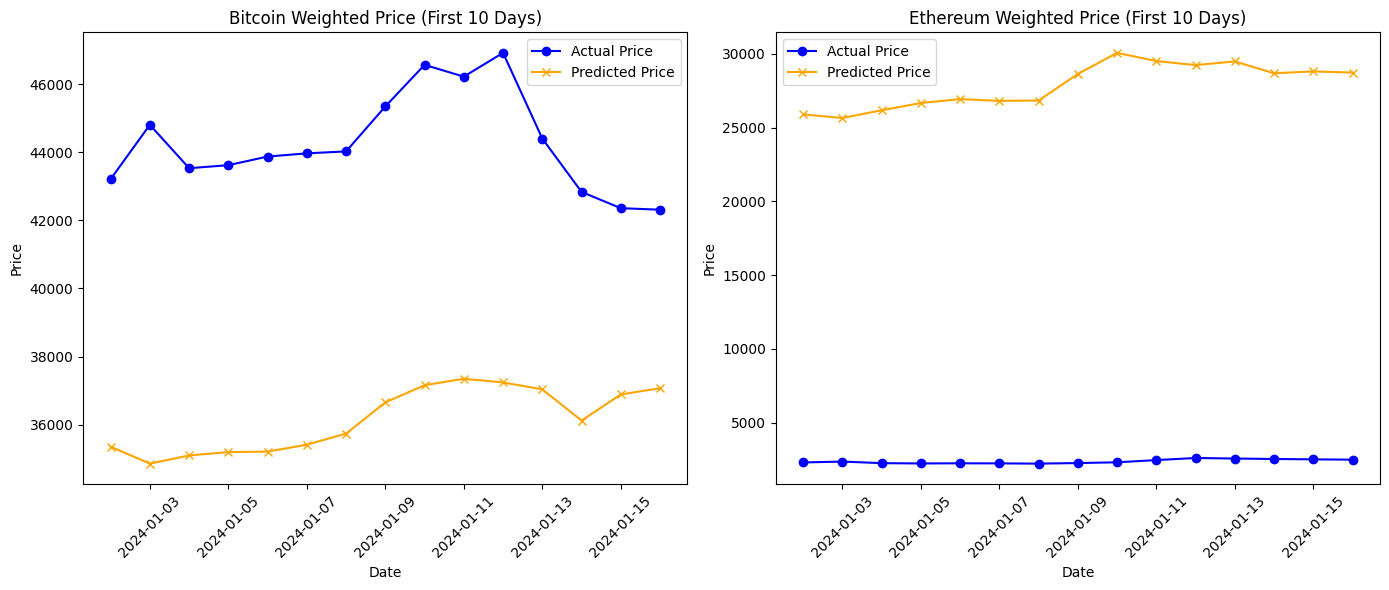

43209.4951171875
35354.05
25894.084


<ipython-input-47-8a3681523a74>:41: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print( btc_future_actual['Weighted_Price'][0])


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Convert predictions and actual values to DataFrames for easy plotting
btc_actual_15_days = btc_future_actual['Weighted_Price'][:15].values
eth_actual_15_days = eth_future_actual['Weighted_Price'][:15].values

# The predicted values from the loop (first 10 days)
btc_pred_15_days = btc_future_predictions[:15].flatten()
eth_pred_15_days = eth_future_predictions[:15].flatten()

# Define dates for plotting
dates = pd.date_range(start='2024-01-02', periods=15, freq='D')

# Plotting
plt.figure(figsize=(14, 6))

# Bitcoin plot
plt.subplot(1, 2, 1)
plt.plot(dates, btc_actual_15_days, label='Actual Price', marker='o', color='blue')
plt.plot(dates, btc_pred_15_days, label='Predicted Price', marker='x', color='orange')
plt.title("Bitcoin Weighted Price (First 10 Days)")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.xticks(rotation=45)

# Ethereum plot
plt.subplot(1, 2, 2)
plt.plot(dates, eth_actual_15_days, label='Actual Price', marker='o', color='blue')
plt.plot(dates, eth_pred_15_days, label='Predicted Price', marker='x', color='orange')
plt.title("Ethereum Weighted Price (First 10 Days)")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.xticks(rotation=45)

# Display the plots
plt.tight_layout()
plt.show()
print( btc_future_actual['Weighted_Price'][0])
print( btc_pred_15_days[0])
print( eth_pred_15_days[0])

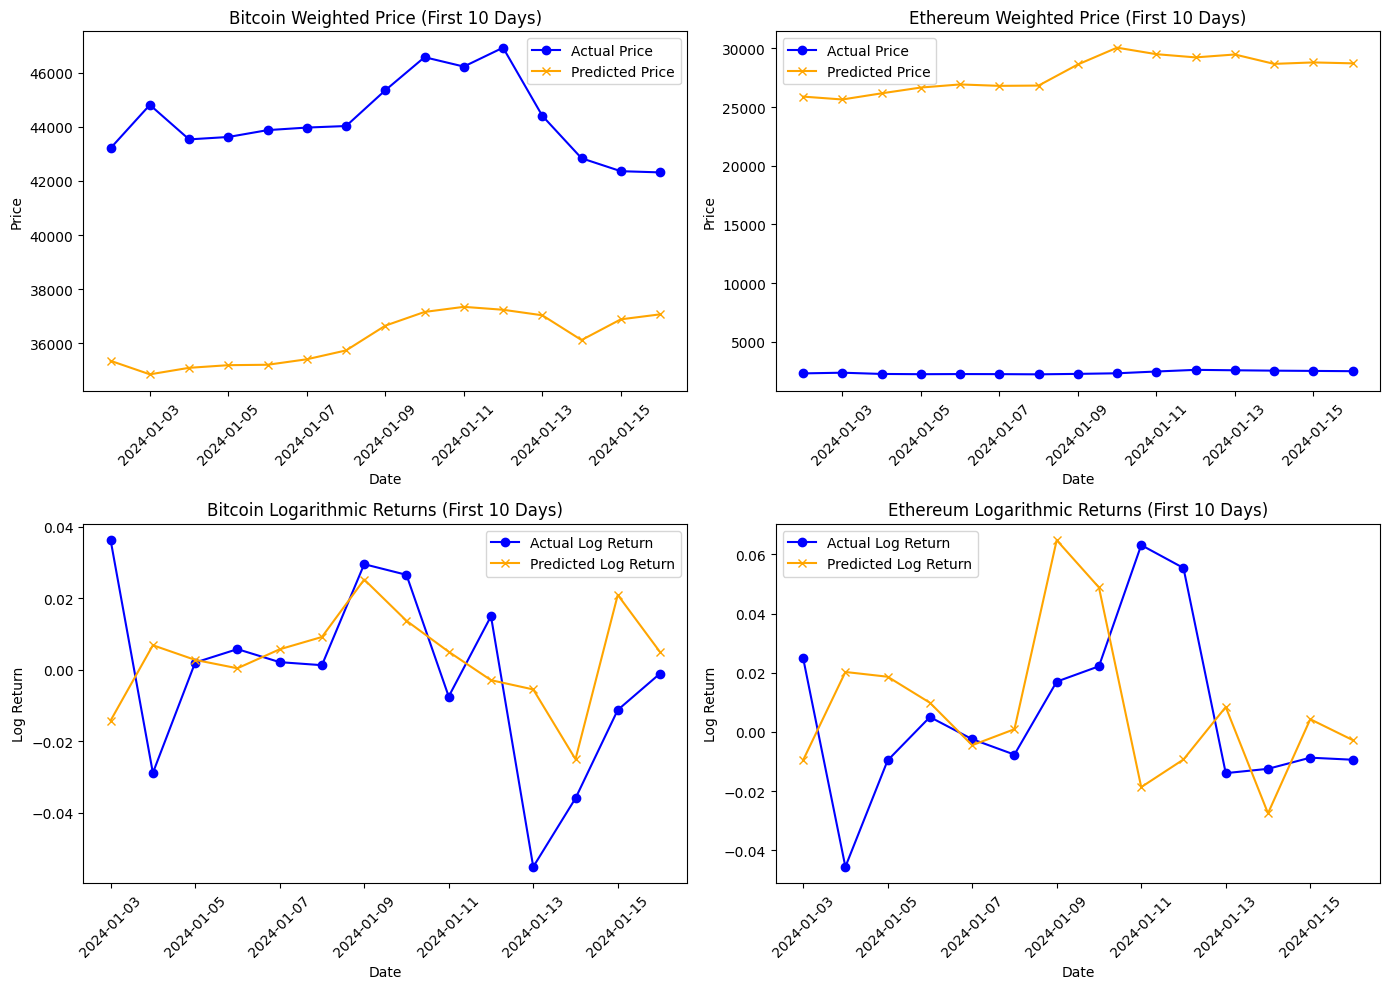

In [ ]:
# Calculate daily logarithmic returns for actual and predicted values
btc_actual_log_returns = np.log(btc_actual_15_days[1:] / btc_actual_15_days[:-1])
eth_actual_log_returns = np.log(eth_actual_15_days[1:] / eth_actual_15_days[:-1])

btc_pred_log_returns = np.log(btc_pred_15_days[1:] / btc_pred_15_days[:-1])
eth_pred_log_returns = np.log(eth_pred_15_days[1:] / eth_pred_15_days[:-1])

# Define dates for plotting (adjusted for log returns since we're comparing differences)
log_return_dates = dates[1:]

# Plotting
plt.figure(figsize=(14, 10))

# Bitcoin Price Comparison Plot
plt.subplot(2, 2, 1)
plt.plot(dates, btc_actual_15_days, label='Actual Price', marker='o', color='blue')
plt.plot(dates, btc_pred_15_days, label='Predicted Price', marker='x', color='orange')
plt.title("Bitcoin Weighted Price (First 10 Days)")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.xticks(rotation=45)

# Ethereum Price Comparison Plot
plt.subplot(2, 2, 2)
plt.plot(dates, eth_actual_15_days, label='Actual Price', marker='o', color='blue')
plt.plot(dates, eth_pred_15_days, label='Predicted Price', marker='x', color='orange')
plt.title("Ethereum Weighted Price (First 10 Days)")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.xticks(rotation=45)

# Bitcoin Logarithmic Returns
plt.subplot(2, 2, 3)
plt.plot(log_return_dates, btc_actual_log_returns, label='Actual Log Return', marker='o', color='blue')
plt.plot(log_return_dates, btc_pred_log_returns, label='Predicted Log Return', marker='x', color='orange')
plt.title("Bitcoin Logarithmic Returns (First 10 Days)")
plt.xlabel("Date")
plt.ylabel("Log Return")
plt.legend()
plt.xticks(rotation=45)

# Ethereum Logarithmic Returns
plt.subplot(2, 2, 4)
plt.plot(log_return_dates, eth_actual_log_returns, label='Actual Log Return', marker='o', color='blue')
plt.plot(log_return_dates, eth_pred_log_returns, label='Predicted Log Return', marker='x', color='orange')
plt.title("Ethereum Logarithmic Returns (First 10 Days)")
plt.xlabel("Date")
plt.ylabel("Log Return")
plt.legend()
plt.xticks(rotation=45)

# Display the plots
plt.tight_layout()
plt.show()